# Beam deflection study
Cantilever under a tip load, $\delta = \frac{P L^3}{3 E I}$. We sweep **load** and **length**, then fit.

- steel, $E$ = 200 GPa
- rectangular section, `I = b h^3 / 12`

| Symbol | Meaning | Unit |
|---|---|---|
| P | tip load | N |
| L | length | m |
| E | modulus | Pa |

In [1]:
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
E, I = 200e9, 8.33e-6
print(f'E = {E:.3e} Pa, I = {I:.3e} m^4')

E = 2.000e+11 Pa, I = 8.330e-06 m^4


In [2]:
L = np.linspace(0.5, 3.0, 11)
P = np.array([500, 1000, 2000])
delta = P[:, None] * L[None, :]**3 / (3 * E * I)
df = pd.DataFrame(delta.T * 1e3, index=pd.Index(L.round(2), name='L [m]'), columns=[f'P={p} N' for p in P])
df

,P=500 N,P=1000 N,P=2000 N
L [m],,,
0.50,0.012505,0.025010,0.050020
0.75,0.042204,0.084409,0.168818
1.00,0.100040,0.200080,0.400160
1.25,0.195391,0.390781,0.781563
1.50,0.337635,0.675270,1.350540
1.75,0.536152,1.072304,2.144608
2.00,0.800320,1.600640,3.201281
2.25,1.139518,2.279037,4.558073
2.50,1.563125,3.126251,6.252501


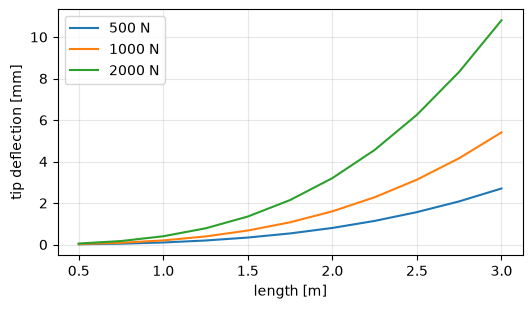

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for p, row in zip(P, delta):
    ax.plot(L, row * 1e3, label=f'{p} N')
ax.set_xlabel('length [m]'); ax.set_ylabel('tip deflection [mm]'); ax.legend(); ax.grid(alpha=.3)
plt.show()

In [4]:
for step in range(120):
    residual = 1.0 / (step + 1) ** 1.7
    print(f'iter {step:4d}  residual {residual:.6e}  dt 1.0e-3')

iter    0  residual 1.000000e+00  dt 1.0e-3
iter    1  residual 3.077861e-01  dt 1.0e-3
iter    2  residual 1.544877e-01  dt 1.0e-3
iter    3  residual 9.473229e-02  dt 1.0e-3
iter    4  residual 6.482626e-02  dt 1.0e-3
iter    5  residual 4.754916e-02  dt 1.0e-3
iter    6  residual 3.658755e-02  dt 1.0e-3
iter    7  residual 2.915728e-02  dt 1.0e-3
iter    8  residual 2.386644e-02  dt 1.0e-3
iter    9  residual 1.995262e-02  dt 1.0e-3
iter   10  residual 1.696807e-02  dt 1.0e-3
iter   11  residual 1.463497e-02  dt 1.0e-3
iter   12  residual 1.277310e-02  dt 1.0e-3
iter   13  residual 1.126114e-02  dt 1.0e-3
iter   14  residual 1.001486e-02  dt 1.0e-3
iter   15  residual 8.974206e-03  dt 1.0e-3
iter   16  residual 8.095372e-03  dt 1.0e-3
iter   17  residual 7.345760e-03  dt 1.0e-3
iter   18  residual 6.700680e-03  dt 1.0e-3
iter   19  residual 6.141140e-03  dt 1.0e-3
iter   20  residual 5.652326e-03  dt 1.0e-3
iter   21  residual 5.222536e-03  dt 1.0e-3
iter   22  residual 4.842422e-03

In [5]:
def stiffness(L, E, I):
    return 3 * E * I / L**3

k = stiffness(L, E, I_section)
k

NameError: name 'I_section' is not defined

In [6]:
df.describe()

,P=500 N,P=1000 N,P=2000 N
count,11.000000,11.000000,11.000000
mean,0.864408,1.728817,3.457633
std,0.907697,1.815394,3.630787
min,0.012505,0.025010,0.050020
25%,0.147715,0.295431,0.590861
50%,0.536152,1.072304,2.144608
75%,1.351322,2.702644,5.405287
max,2.701080,5.402161,10.804322


## Notes
The fit below is a placeholder, run it after the sweep.